# 00 · Los datos y el problema

**Taller 3 de RL (MIAX) · Ejecución de una orden CARE de compra con Repsol.**

Antes de entrenar nada, este notebook responde a tres preguntas: **qué datos tenemos**, **qué tiene que decidir el agente**
y **cuánto cuesta hacerlo bien o mal**. Al final quedan medidas las referencias que usan los cuatro ejercicios.

| Sección | Pregunta |
|---|---|
| 1 | ¿Qué hay en los datos? |
| 2 | ¿Cómo es un día de mercado? |
| 3 | ¿Qué pasa en todos los días? Volumen, spread y volatilidad |
| 4 | ¿Qué es un episodio y qué ve el agente? |
| 5 | ¿Cuánto cuesta comprar? VWAP y spread |
| 6 | ¿Funciona el entorno? Invariantes |
| 7 | Referencias: TWAP, aleatorio y casos extremos |

## 0. El problema en una frase

> Un cliente nos pide comprar **n títulos** en las próximas **N ventanas de 5 s** (entre 33 y 50 minutos). En cada ventana
> decidimos **comprar 1 título al ask** o **esperar**. Queremos completar la orden pagando lo menos posible frente al
> **VWAP del mercado** en ese intervalo.

Sin impacto de mercado ni costes (simplificación del enunciado). El ej. 2 pide que el agente aprenda a repartir las compras
**como un TWAP**: una cada N/n ventanas, en línea recta.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath("."))   # ejecutar desde notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import data as dt, rewards as rw, protocol as pr, plots as pl
from common.env import BestExecutionEnv
from common.agents import TWAPAgent
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
C_MKT, C_ALGO, C_MID = pl.MKT, pl.ALGO, pl.MID
%matplotlib inline

## 1. Qué hay en los datos

`rep_data.pkl` es un diccionario `{train, val, test}` con **un DataFrame por día**: una fila cada 5 s entre las 13:00 y
las 17:25, con el primer nivel del libro.

| Columna | Significado |
|---|---|
| `ask1` / `bid1` | Mejor precio de venta / de compra |
| `vask1` / `vbid1` | Títulos disponibles a ese precio |
| `last` | Último precio negociado |
| `cumvol` | Volumen acumulado del día (la diferencia entre filas = títulos negociados en esos 5 s) |

In [2]:
DATA = dt.load("REP")
rows = []
for split, days in DATA.items():
    keys = list(days)
    first, last = days[keys[0]], days[keys[-1]]
    rows.append({"split": split, "días": len(keys), "desde": first.index[0].date(), "hasta": last.index[0].date(),
                 "filas por día": int(np.median([len(d) for d in days.values()])),
                 "horario": f"{first.index[0]:%H:%M}–{first.index[-1]:%H:%M}"})
pd.DataFrame(rows).set_index("split")

,días,desde,hasta,filas por día,horario
split,,,,,
train,60,2018-01-02,2018-03-26,3181,13:00–17:25
val,30,2019-01-02,2019-02-12,3181,13:00–17:25
test,30,2019-02-13,2019-03-26,3181,13:00–17:25


In [3]:
train = DATA["train"]
day0 = list(train)[0]
train[day0].head()

,ask1,bid1,vask1,vbid1,last,cumvol,date
time,,,,,,,
2018-01-02 13:00:00,15.00,14.995,1368.0,1878.0,15.000,1.429e+06,2018-01-02
2018-01-02 13:00:05,15.01,15.005,1308.0,1.0,15.000,1.431e+06,2018-01-02
2018-01-02 13:00:10,15.01,15.000,2988.0,5438.0,15.005,1.432e+06,2018-01-02
2018-01-02 13:00:15,15.01,15.000,2158.0,7941.0,15.005,1.432e+06,2018-01-02
2018-01-02 13:00:20,15.01,15.000,2138.0,10009.0,15.005,1.432e+06,2018-01-02


**Lectura:**
- **Train:** 60 días, del 2 de enero al 26 de marzo de 2018.
- **Val:** 30 días, del 2 de enero al 12 de febrero de 2019.
- **Test:** 30 días, del 13 de febrero al 26 de marzo de 2019.
- Cada día tiene entre 3.177 y 3.181 filas, sin huecos ni valores vacíos.

Trabajamos con **train**: el enunciado pide las figuras en train y no exige validación.

## 2. Un día de mercado

Arriba, el precio medio (mid) con el spread. Abajo, el volumen negociado en cada ventana de 5 s y el acumulado del día.

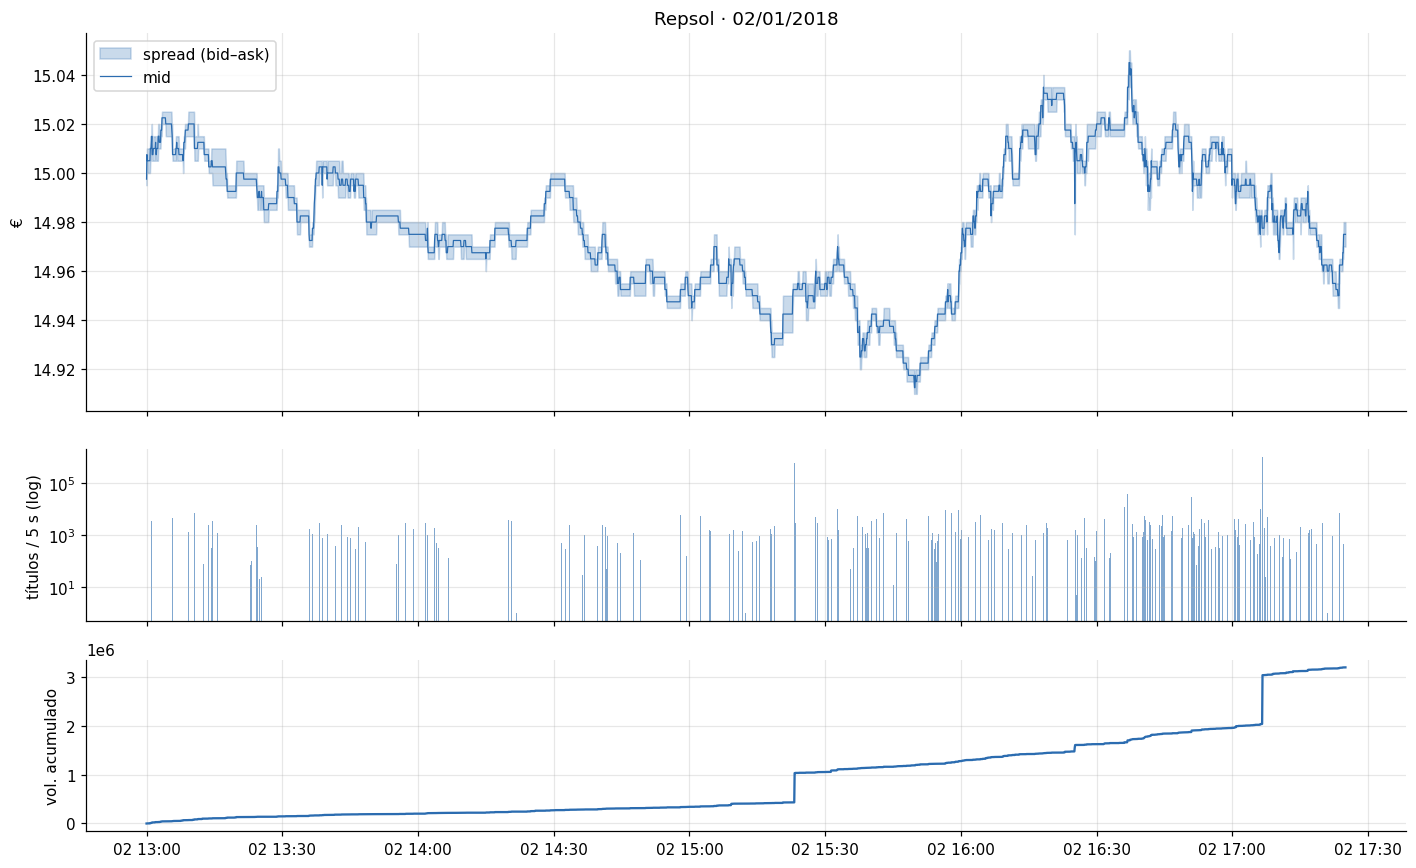

In [4]:
df = train[day0]
mid = (df.ask1 + df.bid1) / 2
vol = df.cumvol.diff().clip(lower=0).fillna(0)
fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1, 1]})
ax[0].fill_between(df.index, df.bid1, df.ask1, color=C_MKT, alpha=0.25, label="spread (bid–ask)")
ax[0].plot(mid, color=C_MKT, lw=0.8, label="mid")
ax[0].set_title(f"Repsol · {df.index[0]:%d/%m/%Y}"); ax[0].legend(loc="upper left"); ax[0].set_ylabel("€")
ax[1].bar(df.index, vol, width=4/86400, color=C_MKT, alpha=0.6); ax[1].set_yscale("log"); ax[1].set_ylabel("títulos / 5 s (log)")
ax[2].plot(df.cumvol - df.cumvol.iloc[0], color=C_MKT); ax[2].set_ylabel("vol. acumulado")
plt.tight_layout()

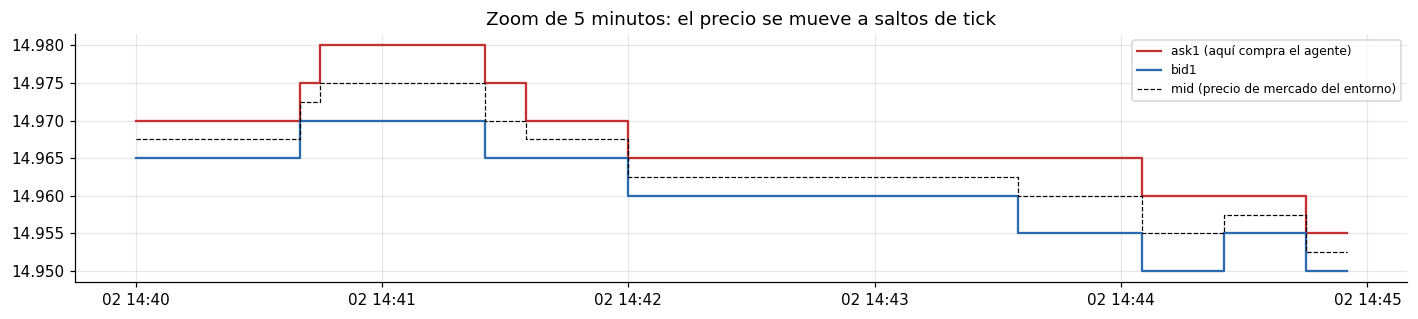

In [5]:
zoom = df.iloc[1200:1260]   # 5 minutos
fig, ax = plt.subplots(figsize=(13, 3))
ax.step(zoom.index, zoom.ask1, where="post", color=C_MID, label="ask1 (aquí compra el agente)")
ax.step(zoom.index, zoom.bid1, where="post", color=C_MKT, label="bid1")
ax.step(zoom.index, (zoom.ask1 + zoom.bid1) / 2, where="post", color="k", lw=0.8, ls="--", label="mid (precio de mercado del entorno)")
ax.set_title("Zoom de 5 minutos: el precio se mueve a saltos de tick"); ax.legend(fontsize=8)
plt.tight_layout()

**Lectura:**
- **El precio va a saltos de tick** (0,005 € sobre unos 15 €, unos 3,3 pb). El spread casi siempre es de 1 tick y a veces de 2.
- **El volumen es muy irregular.** La mayoría de ventanas de 5 s no tienen ninguna operación. Además hay operaciones enormes
  puntuales: el 02/01 dos ventanas suman 0,6 y 1 millón de títulos, cerca de la mitad del volumen de la tarde. Por eso el
  eje está en escala logarítmica.

## 3. Todos los días: volumen, spread y volatilidad a lo largo de la sesión

Promedio de los 60 días de train en tramos de 5 minutos.

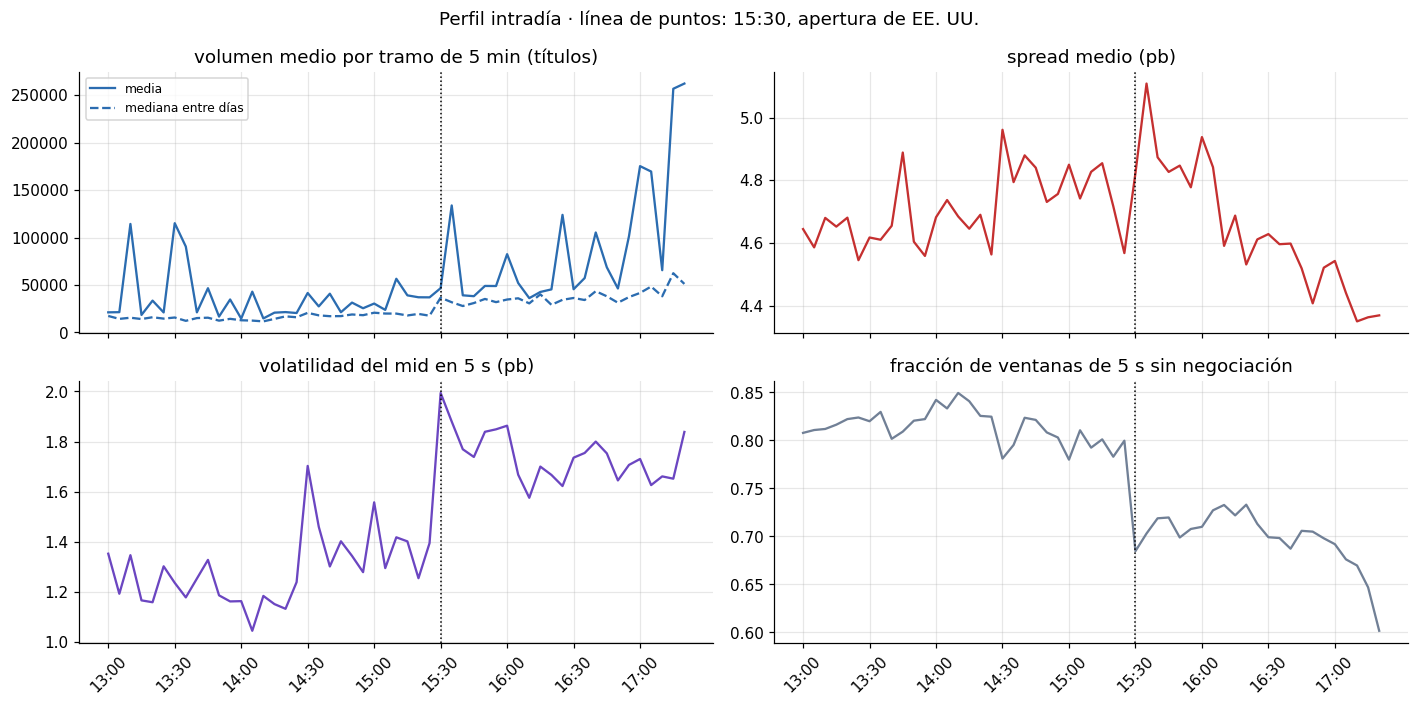

In [6]:
frames = []
for d in train.values():
    m = (d.ask1 + d.bid1) / 2
    frames.append(pd.DataFrame({
        "dia": d.index[0].date(), "hora": d.index.floor("5min").strftime("%H:%M"),
        "vol": d.cumvol.diff().clip(lower=0).fillna(0),
        "spread_bps": (d.ask1 - d.bid1) / m * 1e4,
        "ret_bps": np.log(m).diff().fillna(0) * 1e4,
        "zero": (d.cumvol.diff().fillna(0) == 0),
    }))
allx = pd.concat(frames)
per_day = allx.groupby(["dia", "hora"]).vol.sum().unstack("dia")
prof = allx.groupby("hora").agg(spread=("spread_bps", "mean"), vola=("ret_bps", "std"), zero=("zero", "mean"), filas=("vol", "size"))
prof["vol"], prof["vol_med"] = per_day.mean(axis=1), per_day.median(axis=1)
prof = prof[prof.filas >= prof.filas.median() / 2]   # quita el tramo final incompleto (17:25)
fig, ax = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
for a, col, title, color in [(ax[0, 0], "vol", "volumen medio por tramo de 5 min (títulos)", C_MKT),
                             (ax[0, 1], "spread", "spread medio (pb)", C_MID),
                             (ax[1, 0], "vola", "volatilidad del mid en 5 s (pb)", "#6B46C1"),
                             (ax[1, 1], "zero", "fracción de ventanas de 5 s sin negociación", "#718096")]:
    a.plot(prof.index, prof[col], color=color, label="media"); a.set_title(title)
ax[0, 0].plot(prof.index, prof.vol_med, color=C_MKT, ls="--", label="mediana entre días"); ax[0, 0].legend(fontsize=8)
for a in ax[1]:
    a.set_xticks(prof.index[::6]); a.tick_params(axis="x", rotation=45)
for a in ax.ravel():
    a.axvline("15:30", color="k", ls=":", lw=1)
fig.suptitle("Perfil intradía · línea de puntos: 15:30, apertura de EE. UU."); plt.tight_layout()

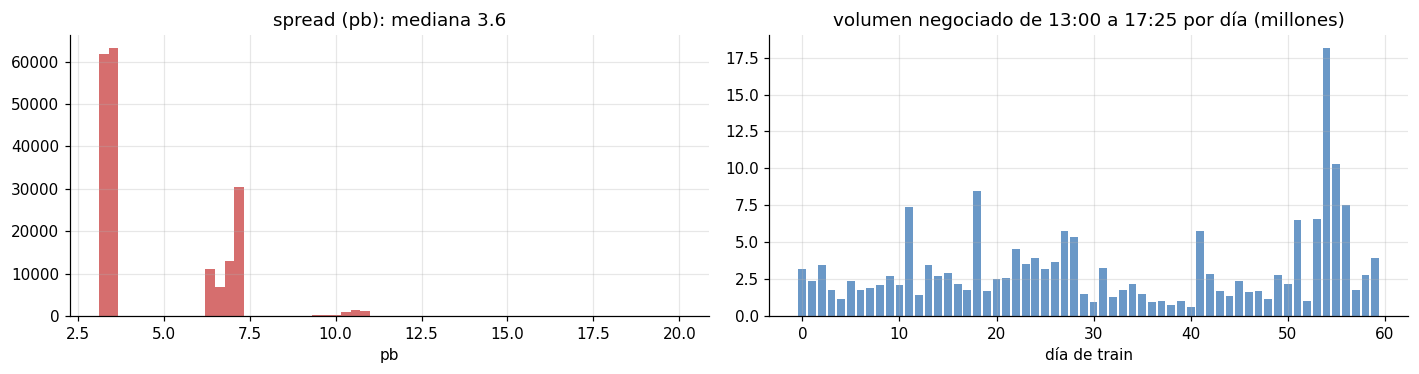

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].hist(allx.spread_bps.clip(upper=20), bins=60, color=C_MID, alpha=0.7)
ax[0].set_title(f"spread (pb): mediana {allx.spread_bps.median():.1f}"); ax[0].set_xlabel("pb")
daily = pd.Series({k: v.cumvol.iloc[-1] - v.cumvol.iloc[0] for k, v in train.items()})
ax[1].bar(range(len(daily)), daily.values / 1e6, color=C_MKT, alpha=0.7)
ax[1].set_title("volumen negociado de 13:00 a 17:25 por día (millones)"); ax[1].set_xlabel("día de train")
plt.tight_layout()

**Lectura:**
- **La sesión tiene dos mitades.**
  - *Volumen:* la mediana pasa de unos 15.000 títulos por tramo de 5 min antes de las 15:30 a unos 35.000 después, y llega a
    50.000-60.000 en el último tramo. La media es mucho más alta y dentada por las operaciones gigantes.
  - *Volatilidad:* sube de unos 1,2 a 1,8 pb cada 5 s con la apertura de EE. UU.
  - *Ventanas sin operaciones:* bajan del 80 % al 70 %, y al 60 % al cierre.
- **El spread medio es de 4,4 a 5,1 pb.** Toca máximo justo después de las 15:30 y se estrecha hacia el cierre. La mediana es
  de 3,6 pb: un tick (≈3,3 pb) la mayor parte del tiempo y dos ticks (≈6,7 pb) con frecuencia.
- **El volumen diario varía entre 0,6 y 18 millones de títulos** según el día.
- **Consecuencia para el TWAP:** reparte por tiempo y no por volumen. Compra lo mismo antes y después de las 15:30, aunque el
  mercado negocie entre 2 y 3 veces más por la tarde. Por eso su VWAP no tiene por qué coincidir con el del mercado.

## 4. Qué es un episodio y qué ve el agente

Cada `reset()` sortea una orden nueva:
- **Día** de train y **hora de inicio** al azar.
- **Duración N** ∈ [400, 600] ventanas de 5 s, es decir, entre 33 y 50 minutos.
- **Tamaño n** = ρ · N con ρ ∈ [7,5 %, 12,5 %]: hay que comprar en ~1 de cada 10 ventanas.
- 60 ventanas previas (`look_back`) quedan disponibles para calcular características del mercado.

El agente solo ve **s = [T, V]**: el tiempo que queda y el volumen que queda, en tanto por uno.

,N,n
min,400.000,30.000
mean,499.312,49.205
max,600.000,73.000


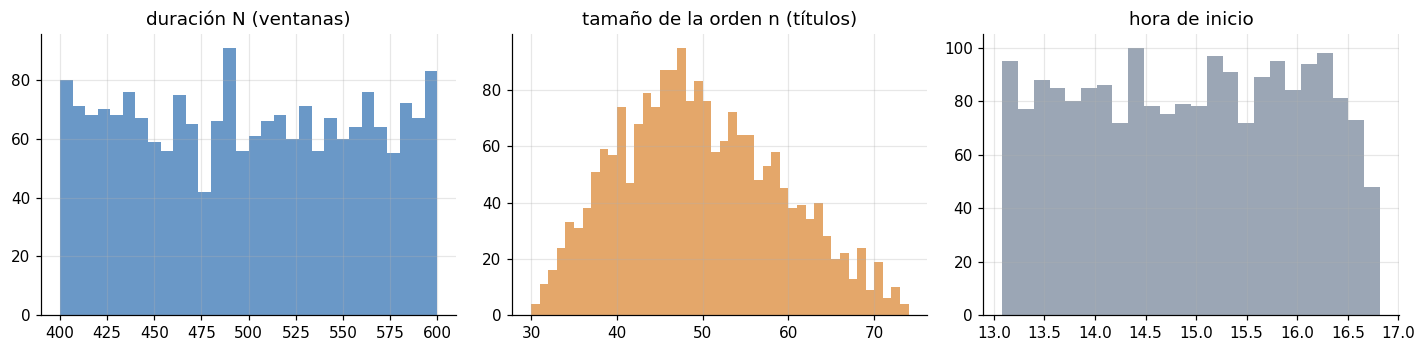

In [8]:
env = BestExecutionEnv(train, seed=0)
eps = []
for _ in range(2000):
    env.reset(); eps.append((env.episode_bins, env.vol_care, env.episode.index[0].strftime("%H:%M")))
eps = pd.DataFrame(eps, columns=["N", "n", "inicio"])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
ax[0].hist(eps.N, bins=30, color=C_MKT, alpha=0.7); ax[0].set_title("duración N (ventanas)")
ax[1].hist(eps.n, bins=range(eps.n.min(), eps.n.max() + 2), color=C_ALGO, alpha=0.7); ax[1].set_title("tamaño de la orden n (títulos)")
ax[2].hist(pd.to_datetime(eps.inicio, format="%H:%M").dt.hour + pd.to_datetime(eps.inicio, format="%H:%M").dt.minute / 60,
           bins=24, color="#718096", alpha=0.7); ax[2].set_title("hora de inicio")
plt.tight_layout()
eps.describe().loc[["min", "mean", "max"]]

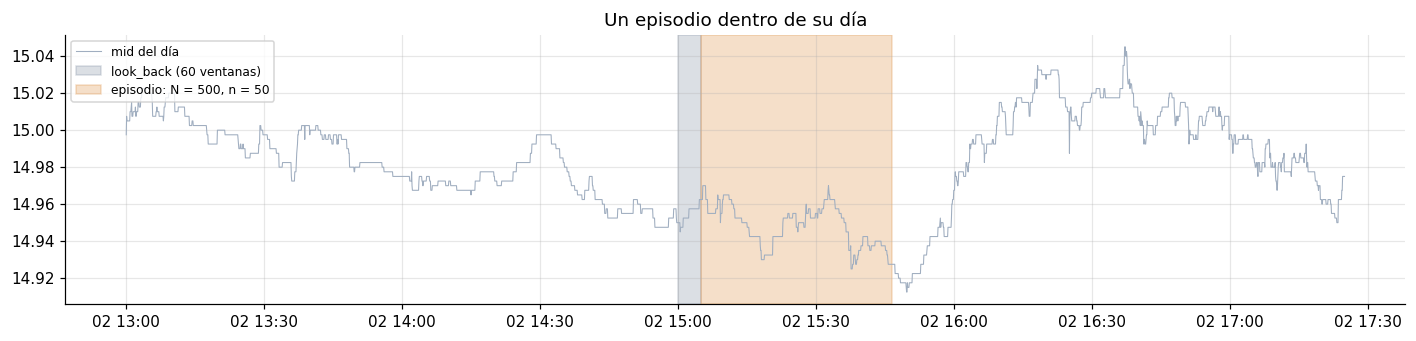

In [9]:
env.reset(day=day0, start_pos=1500, n_bins=500, vol_care=50)
full = train[day0]
m = (full.ask1 + full.bid1) / 2
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.plot(m, color="#A0AEC0", lw=0.7, label="mid del día")
ax.axvspan(env.episode_full.index[0], env.episode.index[0], color="#718096", alpha=0.25, label="look_back (60 ventanas)")
ax.axvspan(env.episode.index[0], env.episode.index[-1], color=C_ALGO, alpha=0.25, label="episodio: N = 500, n = 50")
ax.set_title("Un episodio dentro de su día"); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()

**El bucle de un paso.** `step(a)`: calcula el VWAP de mercado hasta ese momento → ejecuta la acción (compra 1 al `ask1` o
nada) → calcula la recompensa → avanza `state_pos` → comprueba si ha terminado. El episodio termina cuando **se completa la
orden** o **se acaba el tiempo** (con volumen pendiente).

En el plano (T, V) un episodio empieza en (1, 1) y termina cuando V = 0 o T = 0. El TWAP perfecto es la **diagonal**: compra
cuando va igual o por detrás del plan (V ≥ T).

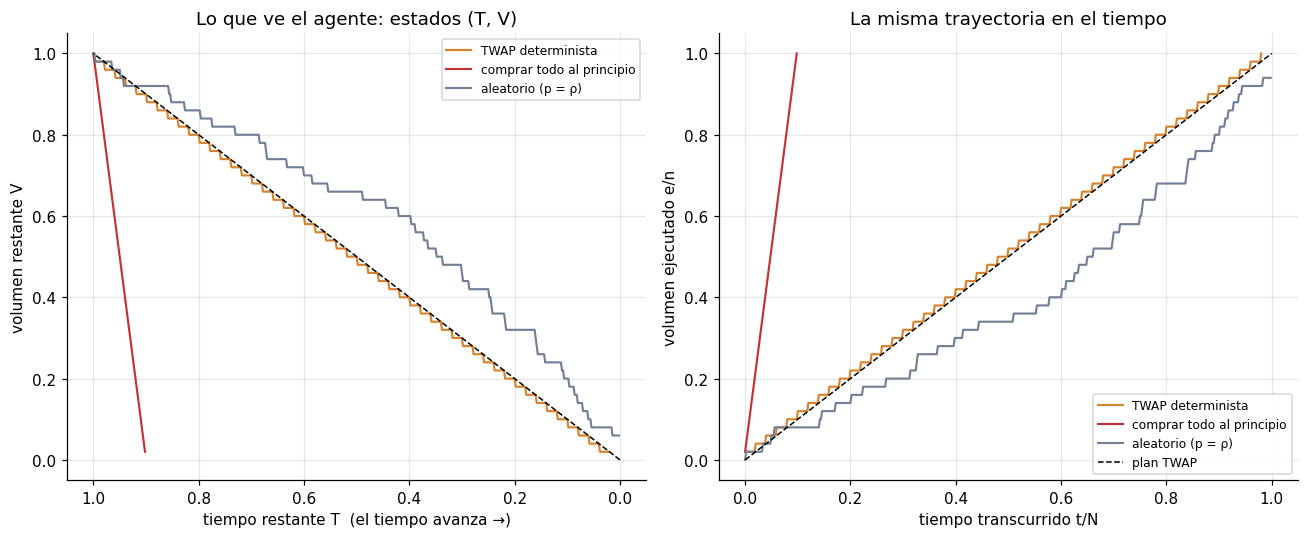

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for agent_name, color, act in [("TWAP determinista", C_ALGO, lambda s, e: int(s[1] >= s[0] - 1e-9)),
                               ("comprar todo al principio", C_MID, lambda s, e: 1),
                               ("aleatorio (p = ρ)", "#718096", lambda s, e: e.action_sample())]:
    e = BestExecutionEnv(train, seed=3); s = e.reset(day=day0, start_pos=1500, n_bins=500, vol_care=50)
    S = [s]
    while True:
        s, _, done, _ = e.step(act(S[-1], e))
        if done: break
        S.append(s)
    S = np.array(S)
    ax[0].plot(S[:, 0], S[:, 1], color=color, lw=1.4, label=agent_name)
    ax[1].plot(np.arange(len(e.vol_hist)) / e.episode_bins, np.cumsum(e.vol_hist) / e.vol_care, color=color, lw=1.4, label=agent_name)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].invert_xaxis()
ax[0].set_xlabel("tiempo restante T  (el tiempo avanza →)"); ax[0].set_ylabel("volumen restante V"); ax[0].set_title("Lo que ve el agente: estados (T, V)")
ax[1].plot([0, 1], [0, 1], "k--", lw=1, label="plan TWAP")
ax[1].set_xlabel("tiempo transcurrido t/N"); ax[1].set_ylabel("volumen ejecutado e/n"); ax[1].set_title("La misma trayectoria en el tiempo")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.tight_layout()

## 5. Cuánto cuesta comprar: VWAP y spread

La métrica del caso es el **VWAP slippage** frente al mercado, en puntos básicos:

$$\text{slippage} = \frac{\text{VWAP}_{\text{mercado}} - \text{VWAP}_{\text{algo}}}{\text{VWAP}_{\text{mercado}}}\cdot 10^4 \qquad (>0 \text{: compramos más barato que el mercado})$$

El entorno valora el mercado al **mid**, pero el agente compra al **ask**. Por tanto, aunque compre en los mismos momentos
que el mercado, **paga medio spread de más**: el slippage esperado de cualquier estrategia agresiva ronda −½ spread.

In [11]:
half = allx.spread_bps.median() / 2
print(f"Medio spread mediano: {half:.2f} pb  →  slippage esperado de comprar agresivo ≈ -{half:.2f} pb")

Medio spread mediano: 1.78 pb  →  slippage esperado de comprar agresivo ≈ -1.78 pb


**Lectura:** el medio spread mediano es de 1,8 pb. En la sección 7, el TWAP determinista obtiene un slippage medio de
−1,8 pb: **exactamente medio spread**. Comprar repartido en el tiempo empata con el mercado, y lo que se pierde es el coste de
cruzar el spread.

## 6. ¿Funciona el entorno? Invariantes

16 pruebas sobre los días de train: rangos de N y n, VWAP calculado a mano, fin por orden completa o por
tiempo, el TWAP determinista con error ≤ 1 título, recompensas, checkpoints y ε.

In [12]:
import unittest
unittest.main(module="common.test_env", argv=["x"], exit=False, verbosity=1)

.

.

.

.

.

.

... (7 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 16 tests in 3.494s

OK


## 7. Referencias

Cuatro políticas sin aprendizaje sobre la **rejilla fija** de evaluación (27 órdenes: N ∈ {400, 500, 600} × ρ ∈ {7,5 %, 10 %,
12,5 %} × 3 días):

| Política | Regla |
|---|---|
| TWAP determinista | Compra si va igual o por detrás del plan (V ≥ T) |
| Aleatoria | Compra con probabilidad ρ |
| Todo al principio | Compra en cada ventana hasta acabar |
| Todo al final | Espera y compra en las últimas n ventanas |

Métricas: **error máximo de seguimiento** frente al plan TWAP (en títulos), **instante de finalización** (t/N), **volumen
pendiente** y **slippage** frente al VWAP de mercado y frente al TWAP.

In [13]:
GRID = pr.make_grid(train, n_days=3, seed=0)

class Rule:
    epsilon, gamma = 0.0, 1.0
    def __init__(self, fn, seed=0): self.fn, self.env, self.rng = fn, None, np.random.default_rng(seed)
    def act(self, s): return self.fn(self, s)
    def set_trainable(self, train=False): pass

POLICIES = {
    "TWAP determinista": TWAPAgent(),
    "aleatoria (p = ρ)": Rule(lambda a, s: a.env.action_sample(rng=a.rng)),
    "todo al principio": Rule(lambda a, s: 1),
    "todo al final": Rule(lambda a, s: int(a.env.state_pos >= a.env.episode_bins - a.env.vol_care)),
}
evals = {name: pr.evaluate(p, train, GRID) for name, p in POLICIES.items()}
pr.save_df(evals["TWAP determinista"], "00_twap_grid"); pr.save_df(evals["aleatoria (p = ρ)"], "00_random_grid")
cols = ["completed_mean", "t_fin_mean", "max_err_mean", "max_err_std", "slippage_bps_mean", "slippage_bps_std", "slippage_vs_twap_bps_mean"]
summary = pd.DataFrame({k: pr.summarize(v)[cols] for k, v in evals.items()}).T
summary.columns = ["completa", "fin (t/N)", "error máx.", "± error", "slippage (pb)", "± slippage", "vs TWAP (pb)"]
summary

,completa,fin (t/N),error máx.,± error,slippage (pb),± slippage,vs TWAP (pb)
TWAP determinista,1.000,0.981,0.900,0.021,-1.774,1.345,0.000
aleatoria (p = ρ),0.481,0.940,7.180,3.598,-2.432,1.822,-0.659
todo al principio,1.000,0.100,44.703,11.262,-2.826,9.182,-1.053
todo al final,1.000,1.000,44.703,11.262,3.439,14.452,5.213


**Lectura de la tabla:**
- **TWAP determinista:** completa todas las órdenes, con un error máximo de 0,9 títulos y un slippage de −1,8 ± 1,3 pb.
- **Aleatoria con p = ρ:** **solo completa el 48 % de las órdenes**. Compra al ritmo correcto en media, pero el azar deja
  volumen pendiente al final en la mitad de los casos, y se separa del plan unos 7 títulos.
- **Casos extremos:** se separan del plan unos 45 títulos. Su slippage varía muchísimo, ±9 pb (todo al principio) y ±14 pb
  (todo al final), frente a ±1,3 del TWAP. Es el **riesgo de timing** del dilema del trader: concentrar las compras es
  apostar a la dirección del precio.

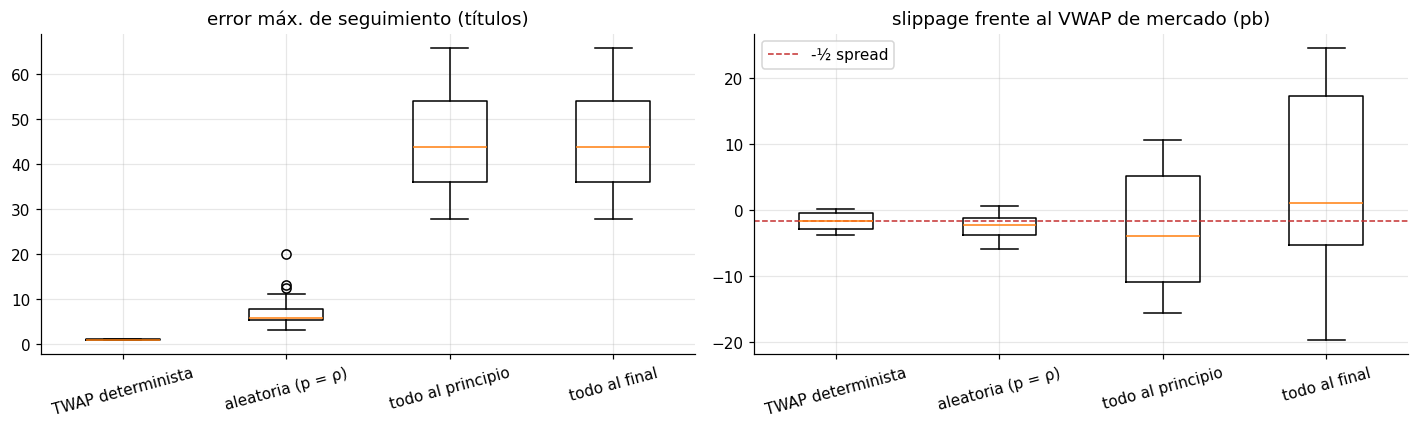

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
names = list(evals)
ax[0].boxplot([evals[n].max_err for n in names], tick_labels=names); ax[0].set_title("error máx. de seguimiento (títulos)")
ax[1].boxplot([evals[n].slippage_bps for n in names], tick_labels=names); ax[1].axhline(-half, color=C_MID, ls="--", lw=1, label="-½ spread")
ax[1].set_title("slippage frente al VWAP de mercado (pb)"); ax[1].legend()
for a in ax: a.tick_params(axis="x", rotation=15)
plt.tight_layout(); pl.save(fig, "00_referencias")

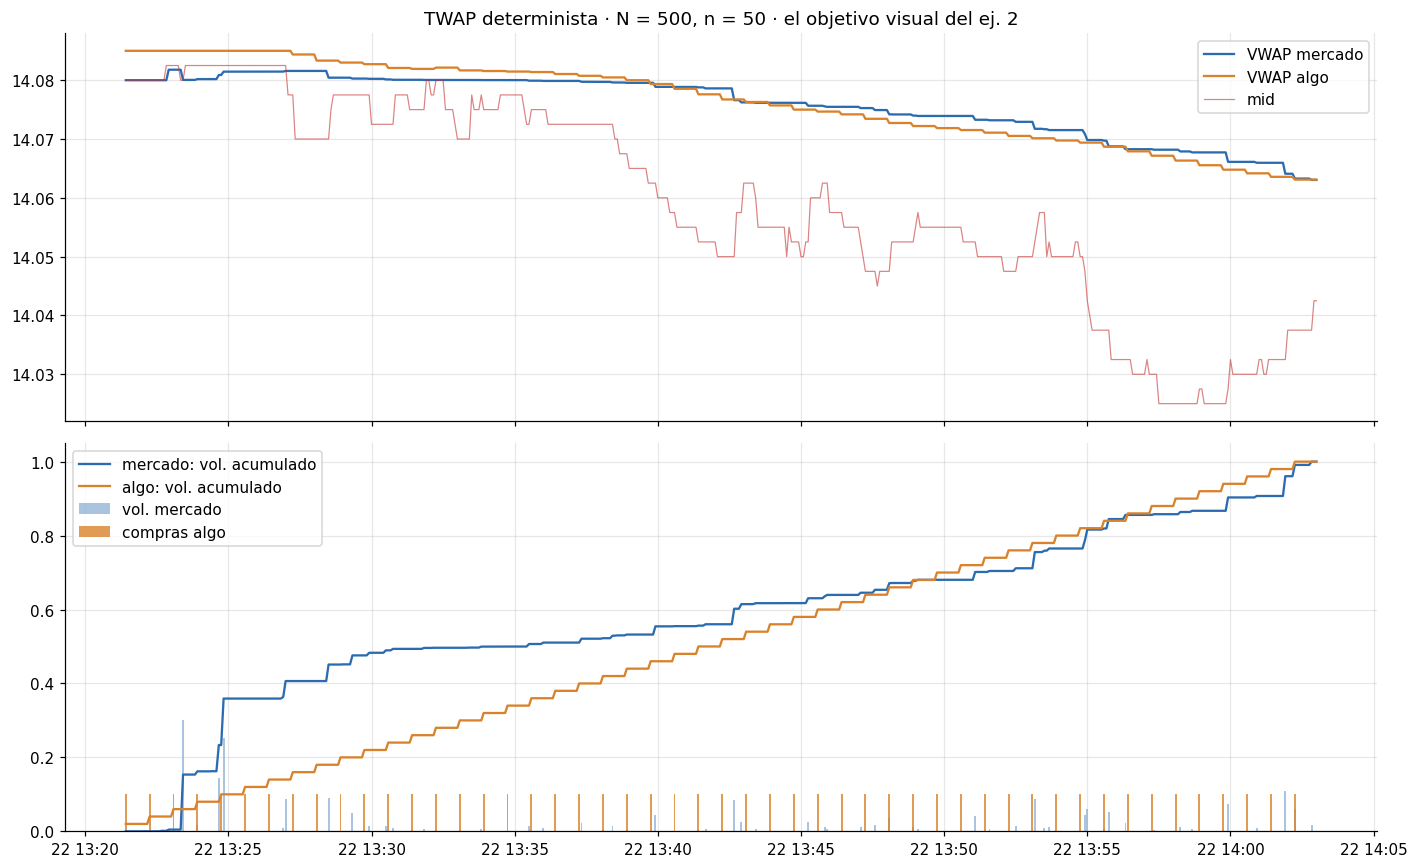

In [15]:
env = BestExecutionEnv(train, seed=0)
cfg = GRID[4]
pr.run_episode(env, TWAPAgent(env), cfg)
pl.plot_results(env, title=f"TWAP determinista · N = {cfg['n_bins']}, n = {cfg['vol_care']} · el objetivo visual del ej. 2", save="00_twap_episodio");

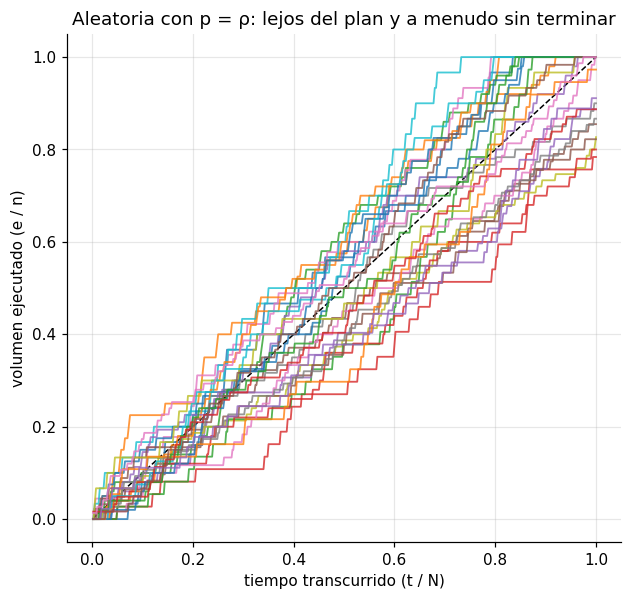

In [16]:
envs = []
for cfg in GRID:
    e = BestExecutionEnv(train, seed=0); rnd = POLICIES["aleatoria (p = ρ)"]; rnd.env = e
    pr.run_episode(e, rnd, cfg); envs.append(e)
pl.plot_trajectories(envs, title="Aleatoria con p = ρ: lejos del plan y a menudo sin terminar", save="00_random_trayectorias");

## 8. Qué nos llevamos para los ejercicios

1. **El ej. 2 tiene un objetivo geométrico:** seguir la diagonal del plano (T, V). El TWAP determinista lo consigue con un
   error de 0,9 títulos, y ese es el listón de «comportamiento similar».
2. **El precio apenas distingue las estrategias razonables:** todas pagan ~½ spread. La recompensa del notebook original, el
   slippage frente al VWAP de todo el episodio, depende sobre todo de cómo se mueva el precio, y el agente no puede verlo con
   [T, V]. Por eso el ej. 2 usa una recompensa de seguimiento del plan.
3. **La aleatoria es el punto de partida del aprendizaje:** se aleja ~7 títulos del plan y deja la mitad de las órdenes
   sin completar. Es la referencia E0 de la métrica de mejora del ej. 3.
4. **Terminar la orden no es trivial:** la mitad de las órdenes aleatorias quedan a medias, y los extremos disparan el riesgo
   de timing. Esto motiva la idea B del ej. 4 (no dejar pendiente y acabar hacia el 90 %) y la necesidad de calibrar su
   penalización.
5. **La sesión cambia a las 15:30:** más volumen, más volatilidad y spread más ancho. Si en el ej. 4 se quiere mejorar el
   precio (idea A), la hora y el volumen reciente son candidatos naturales para el estado.